In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, mean_squared_error, confusion_matrix,
    classification_report
)
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

In [2]:
PROCESSED_DIR = Path("../dataset/processed")
MODELS_DIR = Path("../models")
RESULTS_DIR = Path("../results")
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

In [3]:
X_train = np.load(PROCESSED_DIR / "X_train.npy")
X_val = np.load(PROCESSED_DIR / "X_val.npy")
X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")
y_val = np.load(PROCESSED_DIR / "y_val.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (6183, 17)
X_val: (1325, 17)
X_test: (1326, 17)


In [4]:
class_weights_values = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights = dict(enumerate(class_weights_values))
print("Class weights:", class_weights)

Class weights: {0: np.float64(5.973913043478261), 1: np.float64(0.6813223140495868), 2: np.float64(0.7326697476004266)}


In [5]:
num_classes = len(np.unique(y_train))

ann_model = Sequential([
    Dense(128, activation="relu", input_shape=(X_train.shape[1],)),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(32, activation="relu"),
    Dropout(0.2),

    Dense(num_classes, activation="softmax")
])

ann_model.summary()

c:\Users\DELL\Documents\projet_pfa\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,507 (52.76 KB)

 Trainable params: 13,123 (51.26 KB)

 Non-trainable params: 384 (1.50 KB)

In [6]:
ann_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [7]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=5,
        min_lr=1e-6
    ),
    ModelCheckpoint(
        MODELS_DIR / "ann_model.h5",
        monitor="val_accuracy",
        save_best_only=True
    )
]

In [8]:
history = ann_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/100
187/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3904 - loss: 1.1612

194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5263 - loss: 0.8955 - val_accuracy: 0.7706 - val_loss: 0.6158 - learning_rate: 0.0010
Epoch 2/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7153 - loss: 0.5695 - val_accuracy: 0.7540 - val_loss: 0.5346 - learning_rate: 0.0010
Epoch 3/100
191/194 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7456 - loss: 0.5201

194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7498 - loss: 0.5091 - val_accuracy: 0.8015 - val_loss: 0.4267 - learning_rate: 0.0010
Epoch 4/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7755 - loss: 0.4549 - val_accuracy: 0.7977 - val_loss: 0.4602 - learning_rate: 0.0010
Epoch 5/100
155/194 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7850 - loss: 0.4283

194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7925 - loss: 0.4177 - val_accuracy: 0.8423 - val_loss: 0.3540 - learning_rate: 0.0010
Epoch 6/100
182/194 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8032 - loss: 0.3920

194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8007 - loss: 0.4051 - val_accuracy: 0.8438 - val_loss: 0.3520 - learning_rate: 0.0010
Epoch 7/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8077 - loss: 0.3900 - val_accuracy: 0.8340 - val_loss: 0.3541 - learning_rate: 0.0010
Epoch 8/100
179/194 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8137 - loss: 0.3593

194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8240 - loss: 0.3670 - val_accuracy: 0.8498 - val_loss: 0.3531 - learning_rate: 0.0010
Epoch 9/100
182/194 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8146 - loss: 0.3706

... (2 outputs left out)

194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8522 - loss: 0.2988 - val_accuracy: 0.8853 - val_loss: 0.2598 - learning_rate: 2.0000e-04
Epoch 18/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8569 - loss: 0.2957 - val_accuracy: 0.8838 - val_loss: 0.2806 - learning_rate: 2.0000e-04
Epoch 19/100
178/194 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8591 - loss: 0.2895

194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8601 - loss: 0.2888 - val_accuracy: 0.8906 - val_loss: 0.2595 - learning_rate: 2.0000e-04
Epoch 20/100
172/194 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8594 - loss: 0.2844

194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8601 - loss: 0.2794 - val_accuracy: 0.8958 - val_loss: 0.2442 - learning_rate: 2.0000e-04
Epoch 21/100
168/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8668 - loss: 0.2769

194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8590 - loss: 0.2779 - val_accuracy: 0.8974 - val_loss: 0.2455 - learning_rate: 2.0000e-04
Epoch 22/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8616 - loss: 0.2910 - val_accuracy: 0.8853 - val_loss: 0.2732 - learning_rate: 2.0000e-04
Epoch 23/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8627 - loss: 0.2735 - val_accuracy: 0.8936 - val_loss: 0.2588 - learning_rate: 2.0000e-04
Epoch 24/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8632 - loss: 0.2911 - val_accuracy: 0.8958 - val_loss: 0.2580 - learning_rate: 2.0000e-04
Epoch 25/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8591 - loss: 0.2902 - val_accuracy: 0.8906 - val_loss: 0.2564 - learning_rate: 2.0000e-04
Epoch 26/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8690 - loss: 0.2736 - val_accuracy: 0.8936 - val_loss: 0.2562 - learning_rate: 4.0000e-05
Epoch 27/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy:

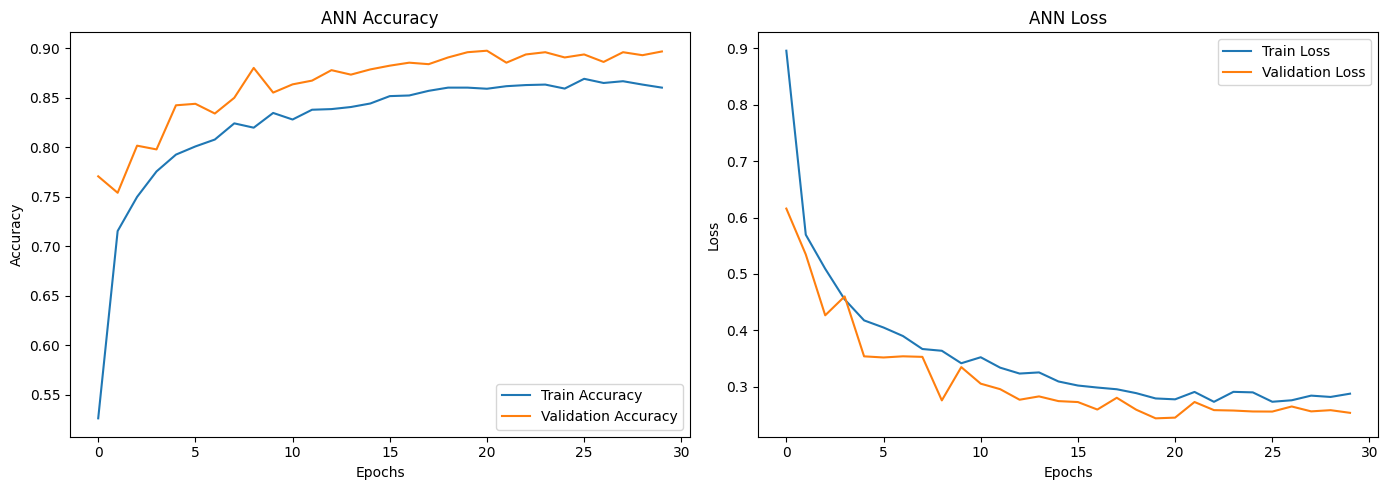

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["accuracy"], label="Train Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("ANN Accuracy")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("ANN Loss")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "ann_training_curves.png", dpi=300)
plt.show()

In [10]:
y_pred = np.argmax(ann_model.predict(X_test), axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

ann_metrics = {
    "Model": "ANN",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "RMSE": rmse
}

print(classification_report(y_test, y_pred, target_names=["Low Risk", "Medium Risk", "High Risk"]))

42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

    Low Risk       0.42      0.88      0.57        74
 Medium Risk       0.92      0.82      0.86       649
   High Risk       0.95      0.94      0.94       603

    accuracy                           0.87      1326
   macro avg       0.76      0.88      0.79      1326
weighted avg       0.91      0.87      0.88      1326



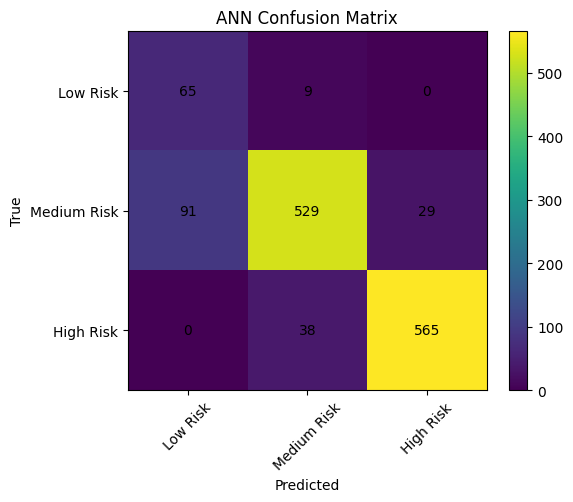

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("ANN Confusion Matrix")
plt.colorbar()

classes = ["Low Risk", "Medium Risk", "High Risk"]
tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation=45)
plt.yticks(tick_marks, classes)

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "ann_confusion_matrix.png", dpi=300)
plt.show()

In [12]:
ann_metrics_df = pd.DataFrame([ann_metrics])
ann_metrics_df.to_csv(RESULTS_DIR / "ann_metrics.csv", index=False)
print(ann_metrics_df)

ann_model.save(MODELS_DIR / "ann_model_final.h5")
print("ANN model saved successfully.")

  Model  Accuracy  Precision    Recall  F1-score      RMSE
0   ANN  0.874057   0.905307  0.874057  0.883558  0.354884
ANN model saved successfully.


In [13]:
import pandas as pd

lstm_metrics_df = pd.read_csv(RESULTS_DIR / "lstm_metrics.csv")
ann_metrics_df = pd.read_csv(RESULTS_DIR / "ann_metrics.csv")

comparison = pd.concat([ann_metrics_df, lstm_metrics_df], ignore_index=True)
comparison.to_csv(RESULTS_DIR / "comparison_results.csv", index=False)
print(comparison)

  Model  Accuracy  Precision    Recall  F1-score      RMSE
0   ANN  0.874057   0.905307  0.874057  0.883558  0.354884
1  LSTM  0.877828   0.902472  0.877828  0.885232  0.349531
